# Sistem Peringatan Dini Banjir Rob di Pesisir Semarang
### Fuzzy Mamdani (dengan pembanding Fuzzy Sugeno)

Tugas Kelompok 01 – Komputasi Lunak, Informatika Universitas Diponegoro

**Input:** tinggi pasang air laut (cm), curah hujan harian (mm/hari), kecepatan angin dari arah laut (km/jam)
**Output:** level siaga rob 0–100 → Aman / Waspada / Siaga / Awas

Cara pakai: klik **Runtime → Run all**. GUI akan muncul di sel paling bawah.

> Data pada notebook ini adalah **data simulasi/hipotetis**, kecuali tinggi pasang 210 cm pada uji kasus Mei 2022.

## 1. Instalasi dan import pustaka

In [ ]:
!pip install -q scikit-fuzzy gradio

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import skfuzzy as fuzz

## 2. Variabel dan fungsi keanggotaan

| Variabel | Himpunan | Dasar batas |
|---|---|---|
| Tinggi pasang (cm), 0–250 | Rendah [0,0,120,160], Sedang [120,160,200], Tinggi [160,200,250,250] | Pasang harian ±148 cm, tanggul 2 m, rob Mei 2022 = 210 cm |
| Curah hujan (mm/hari), 0–200 | Ringan [0,0,20,35], Sedang [20,35,50], Lebat [35,50,200,200] | Kategori BMKG (ringan ≤20, sedang 20–50, lebat ≥50) |
| Kecepatan angin (km/jam), 0–60 | Lemah [0,0,12,20], Sedang [12,24,39], Kencang [29,39,60,60] | Skala Beaufort |
| Level siaga, 0–100 | Aman [0,0,15,35], Waspada [15,35,55], Siaga [45,65,85], Awas [65,85,100,100] | Titik potong: 25, 50, 75 |

Tiga parameter = fungsi segitiga (trimf), empat parameter = fungsi trapesium (trapmf).

In [ ]:
# Semesta pembicaraan (dipakai untuk grafik dan defuzzifikasi)
SEMESTA = {
    'pasang': np.arange(0, 250.1, 0.1),
    'hujan':  np.arange(0, 200.1, 0.1),
    'angin':  np.arange(0, 60.1, 0.1),
    'siaga':  np.arange(0, 100.1, 0.1),
}

# Parameter fungsi keanggotaan: 3 angka = segitiga, 4 angka = trapesium
PARAM = {
    'pasang': {'rendah': [0, 0, 120, 160], 'sedang': [120, 160, 200], 'tinggi': [160, 200, 250, 250]},
    'hujan':  {'ringan': [0, 0, 20, 35],   'sedang': [20, 35, 50],    'lebat':  [35, 50, 200, 200]},
    'angin':  {'lemah':  [0, 0, 12, 20],   'sedang': [12, 24, 39],    'kencang': [29, 39, 60, 60]},
    'siaga':  {'aman': [0, 0, 15, 35], 'waspada': [15, 35, 55], 'siaga': [45, 65, 85], 'awas': [65, 85, 100, 100]},
}

SATUAN = {'pasang': 'cm', 'hujan': 'mm/hari', 'angin': 'km/jam', 'siaga': 'skor'}
JUDUL = {'pasang': 'Tinggi Pasang Air Laut', 'hujan': 'Curah Hujan Harian',
         'angin': 'Kecepatan Angin dari Laut', 'siaga': 'Level Siaga Rob (Output)'}


def mf(x, p):
    """Hitung derajat keanggotaan x (angka atau array) untuk parameter p."""
    x_arr = np.atleast_1d(np.asarray(x, dtype=float))
    hasil = fuzz.trimf(x_arr, p) if len(p) == 3 else fuzz.trapmf(x_arr, p)
    return hasil if np.ndim(x) else float(hasil[0])


# Fungsi keanggotaan output dalam bentuk array (untuk Mamdani)
Y = SEMESTA['siaga']
MF_OUT = {nama: mf(Y, p) for nama, p in PARAM['siaga'].items()}


def fuzzifikasi(pasang, hujan, angin):
    """Langkah 1: ubah nilai crisp menjadi derajat keanggotaan tiap himpunan."""
    nilai = {'pasang': pasang, 'hujan': hujan, 'angin': angin}
    return {var: {h: mf(nilai[var], p) for h, p in PARAM[var].items()} for var in nilai}


fuzzifikasi(110, 45, 15)

{'pasang': {'rendah': 1.0, 'sedang': 0.0, 'tinggi': 0.0},
 'hujan': {'ringan': 0.0,
  'sedang': 0.3333333333333333,
  'lebat': 0.6666666666666666},
 'angin': {'lemah': 0.625, 'sedang': 0.25, 'kencang': 0.0}}

## 3. Rule base (27 rule)

Logika: pasang laut adalah faktor utama, hujan memperparah (air tidak bisa dibuang ke laut saat pasang), angin dari laut mendorong air ke darat. Jika pasang rendah, status paling tinggi Waspada.

In [ ]:
# Format: (pasang, hujan, angin, output)
RULES = [
    # ---- Pasang RENDAH ----
    ('rendah', 'ringan', 'lemah',   'aman'),     # R1
    ('rendah', 'ringan', 'sedang',  'aman'),     # R2
    ('rendah', 'ringan', 'kencang', 'aman'),     # R3
    ('rendah', 'sedang', 'lemah',   'aman'),     # R4
    ('rendah', 'sedang', 'sedang',  'waspada'),  # R5
    ('rendah', 'sedang', 'kencang', 'waspada'),  # R6
    ('rendah', 'lebat',  'lemah',   'waspada'),  # R7
    ('rendah', 'lebat',  'sedang',  'waspada'),  # R8
    ('rendah', 'lebat',  'kencang', 'waspada'),  # R9
    # ---- Pasang SEDANG ----
    ('sedang', 'ringan', 'lemah',   'waspada'),  # R10
    ('sedang', 'ringan', 'sedang',  'waspada'),  # R11
    ('sedang', 'ringan', 'kencang', 'siaga'),    # R12
    ('sedang', 'sedang', 'lemah',   'waspada'),  # R13
    ('sedang', 'sedang', 'sedang',  'siaga'),    # R14
    ('sedang', 'sedang', 'kencang', 'siaga'),    # R15
    ('sedang', 'lebat',  'lemah',   'siaga'),    # R16
    ('sedang', 'lebat',  'sedang',  'siaga'),    # R17
    ('sedang', 'lebat',  'kencang', 'awas'),     # R18
    # ---- Pasang TINGGI ----
    ('tinggi', 'ringan', 'lemah',   'siaga'),    # R19
    ('tinggi', 'ringan', 'sedang',  'awas'),     # R20
    ('tinggi', 'ringan', 'kencang', 'awas'),     # R21
    ('tinggi', 'sedang', 'lemah',   'awas'),     # R22
    ('tinggi', 'sedang', 'sedang',  'awas'),     # R23
    ('tinggi', 'sedang', 'kencang', 'awas'),     # R24
    ('tinggi', 'lebat',  'lemah',   'awas'),     # R25
    ('tinggi', 'lebat',  'sedang',  'awas'),     # R26
    ('tinggi', 'lebat',  'kencang', 'awas'),     # R27
]

tabel_rule = pd.DataFrame(RULES, columns=['Pasang', 'Hujan', 'Angin', 'Level Siaga'])
tabel_rule.index = [f'R{i}' for i in range(1, 28)]
tabel_rule

,Pasang,Hujan,Angin,Level Siaga
R1,rendah,ringan,lemah,aman
R2,rendah,ringan,sedang,aman
R3,rendah,ringan,kencang,aman
R4,rendah,sedang,lemah,aman
R5,rendah,sedang,sedang,waspada
R6,rendah,sedang,kencang,waspada
R7,rendah,lebat,lemah,waspada
R8,rendah,lebat,sedang,waspada
R9,rendah,lebat,kencang,waspada
R10,sedang,ringan,lemah,waspada


## 4. Inferensi Mamdani dan Sugeno

**Mamdani:** α = min(μ pasang, μ hujan, μ angin) → potong himpunan output dengan α (min) → gabungkan semua rule (max) → defuzzifikasi **centroid**:
$$z^* = \frac{\int z\,\mu(z)\,dz}{\int \mu(z)\,dz}$$

**Sugeno orde-0:** rule yang sama, konsekuen berupa konstanta (Aman = 10, Waspada = 35, Siaga = 65, Awas = 90), defuzzifikasi **rata-rata terbobot**:
$$z^* = \frac{\sum \alpha_i z_i}{\sum \alpha_i}$$

In [ ]:
Z_SUGENO = {'aman': 10, 'waspada': 35, 'siaga': 65, 'awas': 90}


def evaluasi_rule(mu):
    """Langkah 2: hitung α (fire strength) tiap rule dengan operator AND = min."""
    hasil = []
    for i, (tp, th, ta, out) in enumerate(RULES, start=1):
        alpha = min(mu['pasang'][tp], mu['hujan'][th], mu['angin'][ta])
        hasil.append((i, tp, th, ta, out, alpha))
    return hasil


def mamdani(pasang, hujan, angin):
    mu = fuzzifikasi(pasang, hujan, angin)
    agregasi = np.zeros_like(Y)
    for _, _, _, _, out, alpha in evaluasi_rule(mu):
        if alpha > 0:
            # Implikasi (min) lalu agregasi (max)
            agregasi = np.fmax(agregasi, np.fmin(alpha, MF_OUT[out]))
    z = fuzz.defuzz(Y, agregasi, 'centroid') if agregasi.any() else 0.0
    return float(z), agregasi


def sugeno(pasang, hujan, angin):
    mu = fuzzifikasi(pasang, hujan, angin)
    rules = evaluasi_rule(mu)
    pembilang = sum(alpha * Z_SUGENO[out] for *_, out, alpha in rules)
    penyebut = sum(alpha for *_, alpha in rules)
    return float(pembilang / penyebut) if penyebut else 0.0


def kategori(z):
    if z < 25:
        return 'Aman'
    if z < 50:
        return 'Waspada'
    if z < 75:
        return 'Siaga'
    return 'Awas'


WARNA = {'Aman': '#2e7d32', 'Waspada': '#f9a825', 'Siaga': '#ef6c00', 'Awas': '#c62828'}

z, _ = mamdani(110, 45, 15)
print(f'Mamdani: {z:.2f} ({kategori(z)})  |  Sugeno: {sugeno(110, 45, 15):.2f}')

Mamdani: 28.25 (Waspada)  |  Sugeno: 29.29


## 5. Detail langkah perhitungan (untuk dicocokkan dengan hitungan manual)
Ganti nilai `P, H, A` sesuai skenario yang dihitung manual.

In [ ]:
P, H, A = 110, 45, 15   # Skenario A

mu = fuzzifikasi(P, H, A)
print('LANGKAH 1 - FUZZIFIKASI')
for var, d in mu.items():
    print(f'  {var:7s}: ' + ', '.join(f'μ{h} = {v:.4f}' for h, v in d.items()))

print('\nLANGKAH 2 - RULE YANG AKTIF (α > 0)')
aktif = [(f'R{i}', tp, th, ta, out, round(a, 4)) for i, tp, th, ta, out, a in evaluasi_rule(mu) if a > 0]
display(pd.DataFrame(aktif, columns=['Rule', 'Pasang', 'Hujan', 'Angin', 'Output', 'α']))

z_m, _ = mamdani(P, H, A)
z_s = sugeno(P, H, A)
print(f'\nLANGKAH 3-4 - Mamdani (centroid) = {z_m:.2f} → {kategori(z_m)}')
print(f'           Sugeno (rata-rata terbobot) = {z_s:.2f} → {kategori(z_s)}')

LANGKAH 1 - FUZZIFIKASI
  pasang : μrendah = 1.0000, μsedang = 0.0000, μtinggi = 0.0000
  hujan  : μringan = 0.0000, μsedang = 0.3333, μlebat = 0.6667
  angin  : μlemah = 0.6250, μsedang = 0.2500, μkencang = 0.0000

LANGKAH 2 - RULE YANG AKTIF (α > 0)


,Rule,Pasang,Hujan,Angin,Output,α
0,R4,rendah,sedang,lemah,aman,0.3333
1,R5,rendah,sedang,sedang,waspada,0.2500
2,R7,rendah,lebat,lemah,waspada,0.6250
3,R8,rendah,lebat,sedang,waspada,0.2500



LANGKAH 3-4 - Mamdani (centroid) = 28.25 → Waspada
           Sugeno (rata-rata terbobot) = 29.29 → Waspada


## 6. Grafik fungsi keanggotaan (untuk laporan subbab 3.3)

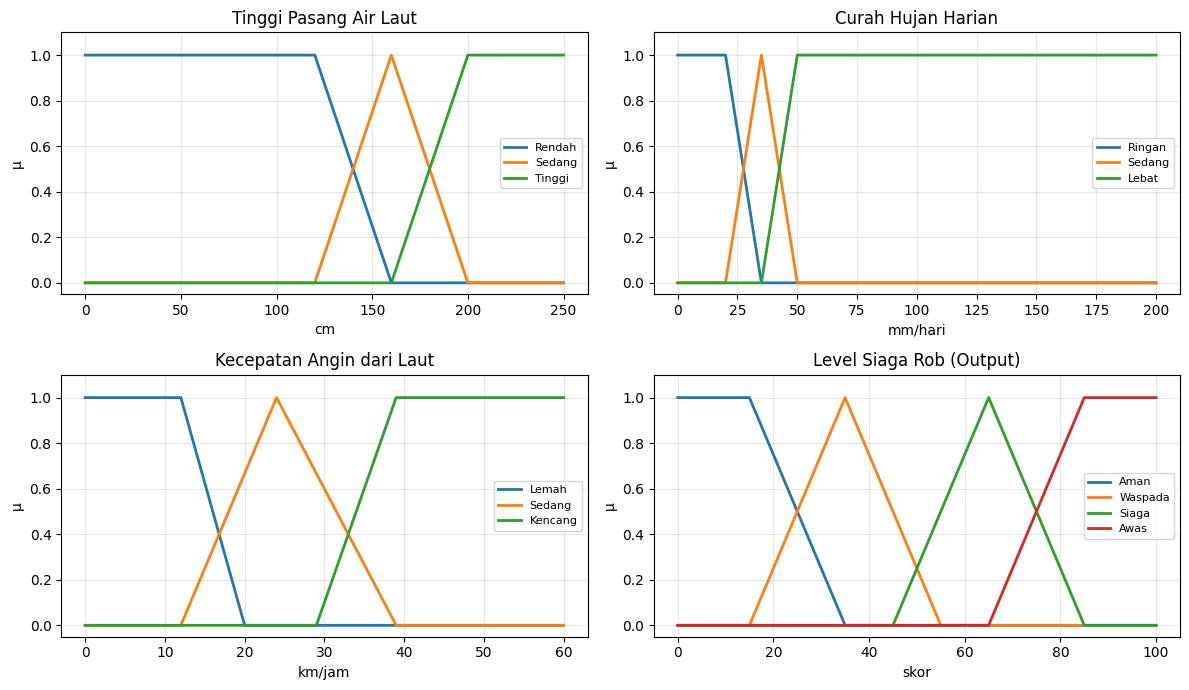

In [ ]:
def gambar_mf(ax, var, x=None):
    for nama, p in PARAM[var].items():
        ax.plot(SEMESTA[var], mf(SEMESTA[var], p), label=nama.capitalize(), linewidth=2)
    if x is not None:
        ax.axvline(x, color='black', linestyle='--', linewidth=1.2)
    ax.set_title(JUDUL[var])
    ax.set_xlabel(SATUAN[var])
    ax.set_ylabel('μ')
    ax.set_ylim(-0.05, 1.1)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)


fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, var in zip(axes.flat, ['pasang', 'hujan', 'angin', 'siaga']):
    gambar_mf(ax, var)
plt.tight_layout()
plt.savefig('fungsi_keanggotaan.png', dpi=200)
plt.show()

## 7. Visualisasi proses inferensi (untuk laporan subbab 3.7 dan 4.2)

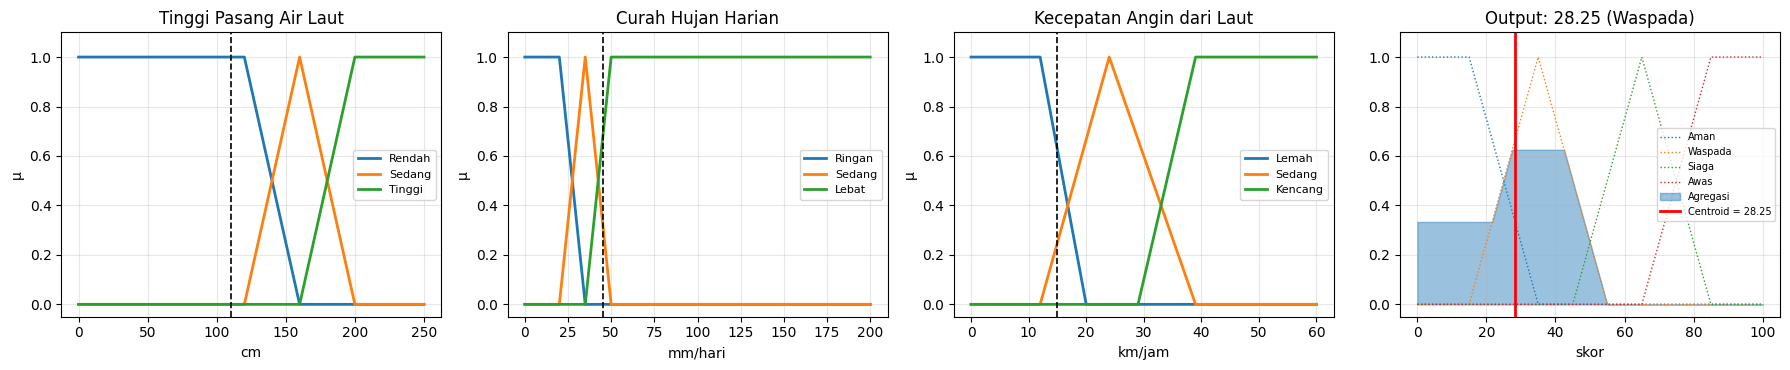

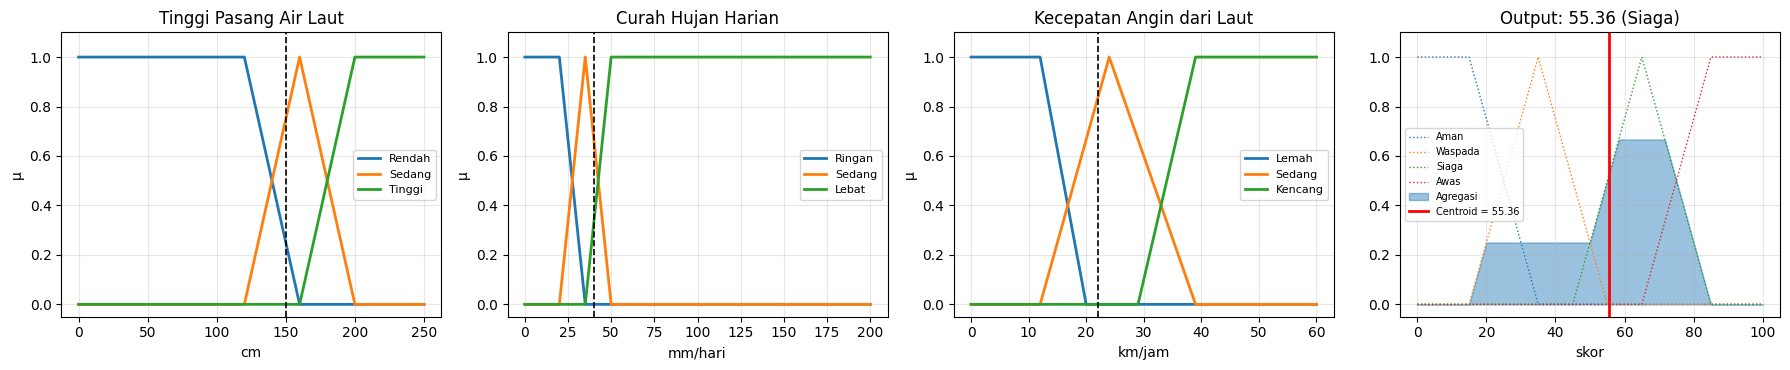

In [ ]:
def gambar_proses(pasang, hujan, angin):
    z, agregasi = mamdani(pasang, hujan, angin)
    fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
    for ax, var, x in zip(axes[:3], ['pasang', 'hujan', 'angin'], [pasang, hujan, angin]):
        gambar_mf(ax, var, x)
    ax = axes[3]
    for nama, kurva in MF_OUT.items():
        ax.plot(Y, kurva, linestyle=':', linewidth=1, label=nama.capitalize())
    ax.fill_between(Y, agregasi, color='tab:blue', alpha=0.45, label='Agregasi')
    ax.axvline(z, color='red', linewidth=2, label=f'Centroid = {z:.2f}')
    ax.set_title(f'Output: {z:.2f} ({kategori(z)})')
    ax.set_xlabel('skor')
    ax.set_ylim(-0.05, 1.1)
    ax.legend(fontsize=7)
    ax.grid(alpha=0.3)
    plt.tight_layout()
    return fig


for nama, (p, h, a) in {'skenario_A': (110, 45, 15), 'skenario_B': (150, 40, 22)}.items():
    fig = gambar_proses(p, h, a)
    fig.savefig(f'proses_{nama}.png', dpi=200)
    plt.show()

## 8. Tabel skenario: Mamdani vs Sugeno (untuk laporan subbab 4.1–4.4)

In [ ]:
SKENARIO = {
    'Normal':                    (100, 5, 10),
    'Pasang harian':             (148, 0, 10),
    'Musim hujan':               (160, 60, 20),
    'Ekstrem':                   (200, 120, 40),
    'Uji Mei 2022*':             (210, 10, 25),
    'Skenario A (hitung manual)': (110, 45, 15),
    'Skenario B (hitung manual)': (150, 40, 22),
}

baris = []
for nama, (p, h, a) in SKENARIO.items():
    z_m, _ = mamdani(p, h, a)
    z_s = sugeno(p, h, a)
    baris.append([nama, p, h, a, round(z_m, 2), kategori(z_m), round(z_s, 2), kategori(z_s)])

tabel = pd.DataFrame(baris, columns=['Skenario', 'Pasang (cm)', 'Hujan (mm)', 'Angin (km/jam)',
                                     'Mamdani', 'Status Mamdani', 'Sugeno', 'Status Sugeno'])
print('*Hanya tinggi pasang 210 cm yang data asli; hujan dan angin adalah asumsi.')
tabel

*Hanya tinggi pasang 210 cm yang data asli; hujan dan angin adalah asumsi.


,Skenario,Pasang (cm),Hujan (mm),Angin (km/jam),Mamdani,Status Mamdani,Sugeno,Status Sugeno
0,Normal,100,5,10,13.17,Aman,10.00,Aman
1,Pasang harian,148,0,10,29.07,Waspada,27.50,Waspada
2,Musim hujan,160,60,20,65.00,Siaga,65.00,Siaga
3,Ekstrem,200,120,40,86.83,Awas,90.00,Awas
4,Uji Mei 2022*,210,10,25,86.60,Awas,90.00,Awas
5,Skenario A (hitung manual),110,45,15,28.25,Waspada,29.29,Waspada
6,Skenario B (hitung manual),150,40,22,55.36,Siaga,55.00,Siaga


## 9. Permukaan keputusan (nilai tambah untuk pembahasan)
Angin ditetapkan 20 km/jam, lalu pasang dan hujan divariasikan.

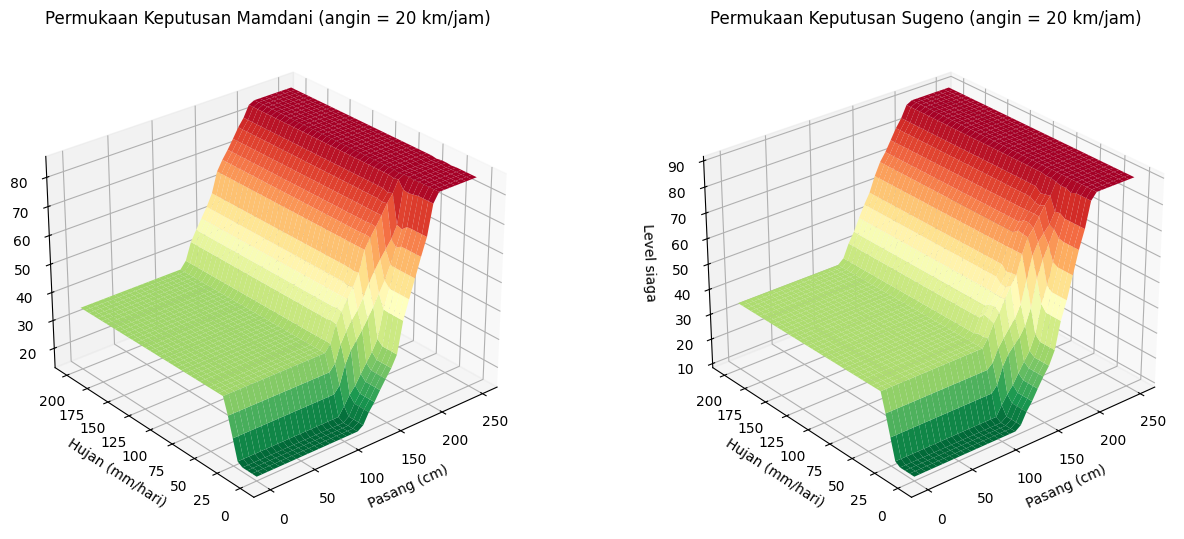

In [ ]:
pp = np.linspace(0, 250, 40)
hh = np.linspace(0, 200, 40)
PP, HH = np.meshgrid(pp, hh)
ZM = np.vectorize(lambda p, h: mamdani(p, h, 20)[0])(PP, HH)
ZS = np.vectorize(lambda p, h: sugeno(p, h, 20))(PP, HH)

fig = plt.figure(figsize=(14, 5.5))
for i, (Z, judul) in enumerate([(ZM, 'Mamdani'), (ZS, 'Sugeno')], start=1):
    ax = fig.add_subplot(1, 2, i, projection='3d')
    ax.plot_surface(PP, HH, Z, cmap='RdYlGn_r', edgecolor='none')
    ax.set_title(f'Permukaan Keputusan {judul} (angin = 20 km/jam)')
    ax.set_xlabel('Pasang (cm)')
    ax.set_ylabel('Hujan (mm/hari)')
    ax.set_zlabel('Level siaga')
    ax.view_init(elev=28, azim=-130)
plt.tight_layout()
plt.savefig('permukaan_keputusan.png', dpi=200)
plt.show()